# Exact Dynamics and Noncommutative Geometric Locking in the Massive Dirac Oscillator
## Publication Figures & Numerical Simulation Notebook (DiracTE Template)

This Jupyter notebook reproduces and reformats all publication figures of the manuscript:
**"Noncommutative Geometric Locking and Relativistic Hall Drift in the Massive Dirac Oscillator"**

Following the presentation, styling, and aesthetic template of [`DiracTE.ipynb`](https://github.com/artnugraha/DiracTE/blob/master/DiracTE.ipynb), all figures incorporate:
- **Typography & Sizing**: Global sizing hierarchy (`SMALL_SIZE = 12`, `MEDIUM_SIZE = 14`, `BIGGER_SIZE = 16`).
- **DiracTE Palette**: Vibrant publication colors (`royalblue`, `crimson`, `darkgreen`, `purple`, `maroon`, `teal`, `black`).
- **Minor Locators**: High-precision `AutoMinorLocator` applied to both axes across all panels.
- **Modular Structure**: Structured code sections `# PREAMBLE`, `# MAIN PART`, and `# PLOTTING`.
- **Publication Quality**: Vector PDF and 250+ DPI PNG exports saved directly into `figures/` for LaTeX integration.

In [5]:
###################################################
# PREAMBLE & GLOBAL CONFIGURATION                 #
###################################################

#----------#
# PREAMBLE #
#----------#

# Mathematical, numerical, and scientific libraries
import sys
from pathlib import Path
import numpy as np
from numpy import linspace, exp, log, pi, zeros, arange, sqrt, sin, cos
from scipy.optimize import brentq
from matplotlib.ticker import AutoMinorLocator
import matplotlib.pyplot as plt

%matplotlib inline

# Style controls (matching DiracTE style)
SMALL_SIZE  = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16

plt.rc('font', size=SMALL_SIZE)        # controls default text sizes
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('xtick', labelsize=MEDIUM_SIZE) # fontsize of the x tick labels
plt.rc('ytick', labelsize=MEDIUM_SIZE) # fontsize of the y tick labels
plt.rc('axes', labelsize=BIGGER_SIZE)  # fontsize of the x and y labels
plt.rc('axes', titlesize=BIGGER_SIZE)  # fontsize of plot titles

# Configure output directories
BASE_DIR = Path.cwd()
if (BASE_DIR / 'New Draft').exists():
    OUT_DIR = BASE_DIR / 'New Draft' / 'figures'
    PLOTS_DIR = BASE_DIR / 'New Draft' / 'Verification' / 'plots'
else:
    OUT_DIR = BASE_DIR / 'figures'
    PLOTS_DIR = BASE_DIR / 'plots'

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name):
    fig.savefig(OUT_DIR / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(OUT_DIR / f'{name}.png', dpi=250, bbox_inches='tight')
    fig.savefig(PLOTS_DIR / f'{name}.png', dpi=250, bbox_inches='tight')
    print(f'Saved: {name}.pdf and {name}.png to {OUT_DIR}')


In [6]:
###################################################
# NONCOMMUTATIVE DIRAC OSCILLATOR NUMERICAL CORE  #
###################################################

#-----------#
# MAIN PART #
#-----------#

# Pauli matrices
sigma_0 = np.eye(2, dtype=complex)
sigma_x = np.array([[0, 1], [1, 0]], dtype=complex)
sigma_y = np.array([[0, -1j], [1j, 0]], dtype=complex)
sigma_z = np.array([[1, 0], [0, -1]], dtype=complex)

def lam2_of(theta, gamma):
    return 2.0 + theta + gamma

def ann(nf):
    return np.diag(np.sqrt(np.arange(1, nf)), 1).astype(complex)

def one_mode_ops(theta, gamma, Delta, nf):
    lam2 = lam2_of(theta, gamma)
    lam = np.sqrt(lam2)
    a = ann(nf)
    ad = a.conj().T
    I = np.eye(nf)
    qx = lam / np.sqrt(2) * (a + ad)
    qy = lam / (1j * np.sqrt(2)) * (a - ad)
    big = lambda s, F: np.kron(s, F)
    ops = dict(
        lam2=lam2,
        qx=big(sigma_0, qx),
        qy=big(sigma_0, qy),
        sx=big(sigma_x, I),
        sy=big(sigma_y, I),
        sz=big(sigma_z, I),
        A=big(sigma_0, a),
    )
    ops['h'] = ops['sx'] @ ops['qx'] + ops['sy'] @ ops['qy'] + Delta * ops['sz']
    return ops

def one_mode_state(phi, chi, nf, n=0):
    psi = np.zeros(2 * nf, complex)
    psi[n] = np.cos(phi / 2)
    psi[nf + n] = np.exp(1j * chi) * np.sin(phi / 2)
    return psi

class Evolver:
    def __init__(self, H, psi0):
        self.E, self.V = np.linalg.eigh(H)
        self.c = self.V.conj().T @ psi0

    def expect(self, O, taus):
        M = self.V.conj().T @ (O @ self.V)
        ph = np.exp(-1j * np.outer(np.asarray(taus, float), self.E)) * self.c
        return np.sum((ph.conj() @ M) * ph, axis=1)

def gammas(theta, gamma, Delta):
    lam2 = lam2_of(theta, gamma)
    E = np.sqrt(Delta ** 2 + 2 * lam2)
    return E, E + Delta, E - Delta

def exact_Z(theta, gamma, Delta, phi, chi, taus, Rx=0.0, Ry=0.0):
    E, Gp, Gm = gammas(theta, gamma, Delta)
    mu = 1 + theta
    return (Rx + 1j * Ry) + 1j * mu * np.sin(phi) / (2 * E) * np.exp(1j * chi) * (
        np.exp(-1j * Gm * taus) - np.exp(1j * Gp * taus))

def exact_all(theta, gamma, Delta, phi, chi, taus, Rx=0.0, Ry=0.0):
    E, Gp, Gm = gammas(theta, gamma, Delta)
    mu, nu = 1 + theta, 1 + gamma
    Z = exact_Z(theta, gamma, Delta, phi, chi, taus, Rx, Ry)
    Zc = Z - (Rx + 1j * Ry)
    W = -1j * nu / mu * Zc
    P = 1j * (Rx + 1j * Ry) + W
    return Z.real, Z.imag, P.real, P.imag

def Delta_of_S_N(S, N):
    return (N - 2) * np.sqrt((S + 2) / (2 * (N - 1)))

def meanfield(theta, gamma, Delta, phi, chi, taus):
    from scipy.integrate import solve_ivp
    al, be = 1 + theta, 1 + gamma

    def f(t, u):
        X, Y, Px, Py, sx, sy, sz = u
        qx, qy = Px + Y, Py - X
        return [al * sx, al * sy, be * sy, -be * sx,
                2 * qy * sz - 2 * Delta * sy,
                -2 * qx * sz + 2 * Delta * sx,
                2 * (qx * sy - qy * sx)]

    u0 = [0, 0, 0, 0, np.sin(phi) * np.cos(chi), np.sin(phi) * np.sin(chi), np.cos(phi)]
    sol = solve_ivp(f, [taus[0], taus[-1]], u0, t_eval=taus, rtol=1e-11, atol=1e-13, method='DOP853')
    return sol.y


## 1. Exact Quantum Dynamics versus Nonlinear Mean-Field Trajectories

The two-dimensional massive Dirac oscillator in non-commutative phase space is described by:
\begin{align}
\hat{H} = v_F \left(\sigma_x \hat{q}_x + \sigma_y \hat{q}_y\right) + \Delta_0 \sigma_z,
\end{align}
where the gauge-invariant coordinates satisfy the deformed algebra:
\begin{align}
[\hat{q}_x, \hat{q}_y] = i\lambda^2, \quad \lambda^2 = 2 + \bar{\theta} + \bar{\gamma}, \quad S = \bar{\theta} + \bar{\gamma}.
\end{align}

The exact Heisenberg dynamics of the centroid operator $\hat{Z}(\tau) = \hat{X}(\tau) + i\hat{Y}(\tau)$ admits the closed-form solution:
\begin{align}
\langle \hat{Z}\rangle(\tau) = (R_x + i R_y) + \frac{i(1+\bar{\theta})\sin\phi}{2\mathcal{E}} e^{i\chi} \left(e^{-i\Gamma_-\tau} - e^{i\Gamma_+\tau}\right),
\end{align}
where $\Gamma_\pm = \mathcal{E} \pm \Delta_0$ and $\mathcal{E} = \sqrt{\Delta_0^2 + 2\lambda^2}$.

When the commensurability condition $\Gamma_+/\Gamma_- = N-1$ is satisfied (here at $S=0.5, \Delta_0=2 \implies N=6$), the exact centroid traces a **closed six-petal rose curve**. In contrast, semiclassical mean-field factorization $\langle \mathbf{q}\sigma_i\rangle \approx \langle \mathbf{q}\rangle\langle\sigma_i\rangle$ destroys the quantum interference, resulting in an unphysical precessing trajectory.

Saved: fig_dynamics.pdf and fig_dynamics.png to d:\COOLYEAH\Research\Non-Commutativity\Draft split\PaperB_exact-main(1)\PaperB_exact-main\New Draft\figures


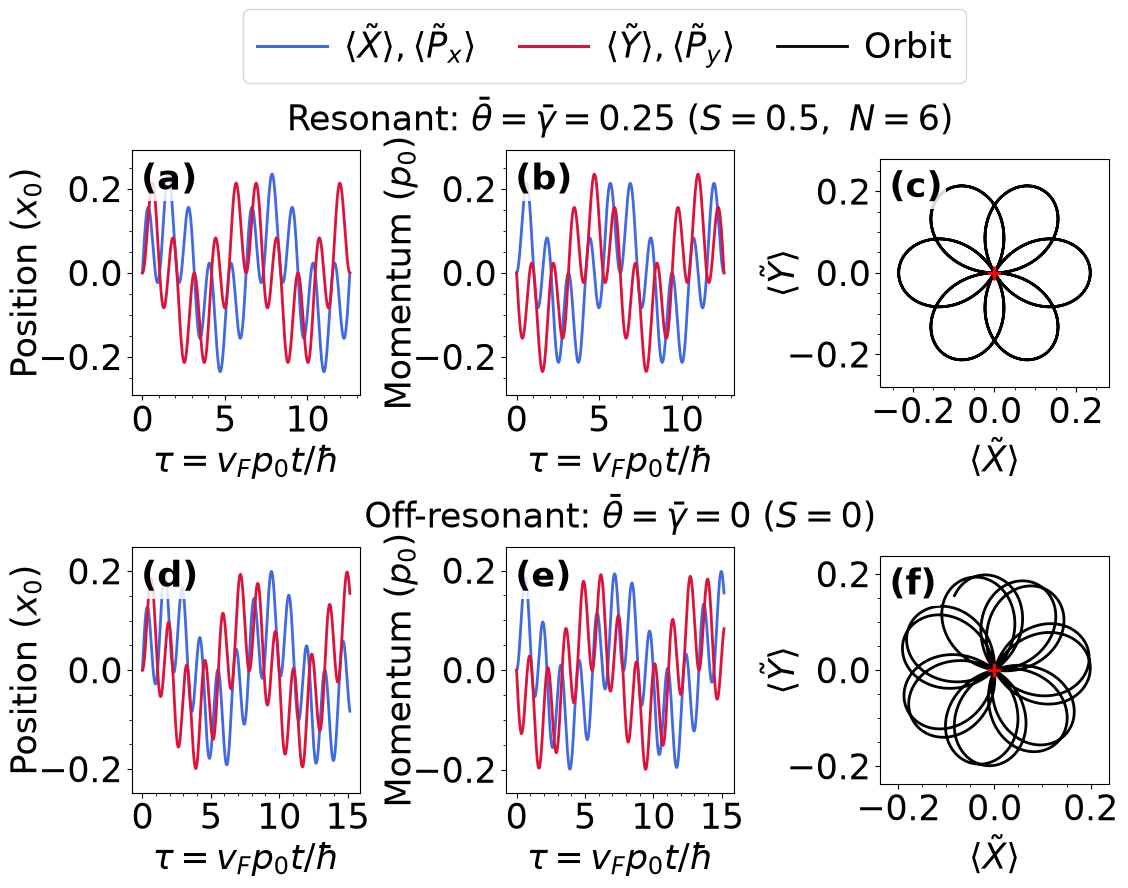

In [7]:
###################################################
# FIGURE 1: EXACT DYNAMICS (SINGLE-COLUMN 25pt)   #
###################################################

FS = 25
Delta, phi, chi = 2.0, 0.6, 0.0

fig, axs = plt.subplots(2, 3, figsize=(12.6, 8.8))
fig.subplots_adjust(wspace=0.64, hspace=0.62, top=0.84)

rows_config = [
    (0.25, 0.25, r"Resonant: $\bar{\theta}=\bar{\gamma}=0.25$ ($S=0.5,\ N=6$)"),
    (0.0, 0.0, r"Off-resonant: $\bar{\theta}=\bar{\gamma}=0$ ($S=0$)")
]
tags = [["(a)", "(b)", "(c)"], ["(d)", "(e)", "(f)"]]

for r_idx, (th, ga, row_title) in enumerate(rows_config):
    E, Gp, Gm = gammas(th, ga, Delta)
    taus = np.linspace(0, 4 * np.pi / Gm, 1600)
    X, Y, Px, Py = exact_all(th, ga, Delta, phi, chi, taus)
    mf = meanfield(th, ga, Delta, phi, chi, taus)
    ax = axs[r_idx]

    ax[0].plot(taus, X, color='royalblue', lw=2.0)
    ax[0].plot(taus, Y, color='crimson', lw=2.0)
    ymax0 = max(np.max(np.abs(X)), np.max(np.abs(mf[0]))) * 1.2
    ax[0].set_ylim(-ymax0, ymax0)
    ax[0].set_yticks([-0.2, 0.0, 0.2])
    ax[0].set_xticks([0, 5, 10] if r_idx == 0 else [0, 5, 10, 15])
    ax[0].set_xlabel(r'$\tau = v_F p_0 t / \hbar$', fontsize=FS)
    ax[0].set_ylabel(r'$\mathrm{Position}\ (x_0)$', fontsize=FS)
    ax[0].yaxis.set_label_coords(-0.38, 0.5)
    ax[0].xaxis.set_minor_locator(AutoMinorLocator(5))
    ax[0].yaxis.set_minor_locator(AutoMinorLocator(4))

    ax[1].plot(taus, Px, color='royalblue', lw=2.0)
    ax[1].plot(taus, Py, color='crimson', lw=2.0)
    ymax1 = max(np.max(np.abs(Px)), np.max(np.abs(mf[2]))) * 1.2
    ax[1].set_ylim(-ymax1, ymax1)
    ax[1].set_yticks([-0.2, 0.0, 0.2])
    ax[1].set_xticks([0, 5, 10] if r_idx == 0 else [0, 5, 10, 15])
    ax[1].set_xlabel(r'$\tau = v_F p_0 t / \hbar$', fontsize=FS)
    ax[1].set_ylabel(r'$\mathrm{Momentum}\ (p_0)$', fontsize=FS)
    ax[1].yaxis.set_label_coords(-0.38, 0.5)
    ax[1].set_title(row_title, fontsize=FS, pad=14)
    ax[1].xaxis.set_minor_locator(AutoMinorLocator(5))
    ax[1].yaxis.set_minor_locator(AutoMinorLocator(4))

    ax[2].plot(X, Y, color='black', lw=2.0)
    ax[2].plot(X[0], Y[0], marker='+', color='red', markersize=10, mew=2.2)
    ax[2].set_aspect('equal', 'box')
    rmax = max(np.max(np.abs(X)), np.max(np.abs(mf[0])), np.max(np.abs(Y)), np.max(np.abs(mf[1]))) * 1.15
    ax[2].set_xlim(-rmax, rmax)
    ax[2].set_ylim(-rmax, rmax)
    ax[2].set_xticks([-0.2, 0.0, 0.2])
    ax[2].set_yticks([-0.2, 0.0, 0.2])
    ax[2].set_xlabel(r'$\langle\tilde{X}\rangle$', fontsize=FS)
    ax[2].set_ylabel(r'$\langle\tilde{Y}\rangle$', fontsize=FS)
    ax[2].yaxis.set_label_coords(-0.34, 0.5)
    ax[2].xaxis.set_minor_locator(AutoMinorLocator(4))
    ax[2].yaxis.set_minor_locator(AutoMinorLocator(4))

    for c_idx in range(3):
        ax[c_idx].tick_params(axis='both', which='major', labelsize=FS)
        ax[c_idx].text(0.04, 0.95, tags[r_idx][c_idx], transform=ax[c_idx].transAxes,
                       va='top', ha='left', fontsize=FS, fontweight='bold',
                       bbox=dict(boxstyle='square,pad=0.10', fc='white', ec='none', alpha=0.85))

handles = [
    plt.Line2D([0], [0], color='royalblue', lw=2.2, label=r'$\langle\tilde{X}\rangle,\langle\tilde{P}_x\rangle$'),
    plt.Line2D([0], [0], color='crimson', lw=2.2, label=r'$\langle\tilde{Y}\rangle,\langle\tilde{P}_y\rangle$'),
    plt.Line2D([0], [0], color='black', lw=2.0, label='Orbit'),
]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.50, 1.02),
           ncol=3, frameon=True, facecolor='white', edgecolor='0.8', fontsize=FS,
           columnspacing=1.2, handletextpad=0.5)

save_figure(fig, 'fig_dynamics')
plt.show()


## 2. Commensurate Locking Phase Diagram

The frequency ratio between the fast zitterbewegung mode ($\Gamma_+$) and the slow cyclotron mode ($\Gamma_-$) determines the topology of the centroid orbits. Resonance occurs when the ratio is an integer:
\begin{align}
\frac{\Gamma_+}{\Gamma_-} = \frac{\mathcal{E} + \tilde{\Delta}}{\mathcal{E} - \tilde{\Delta}} = N - 1, \quad N \in \{3, 4, 5, 6, \dots\}
\end{align}

Solving for the dimensionless mass gap $\tilde{\Delta} = \Delta_0/(v_F p_0)$ yields the analytical **resonance curves**:
\begin{align}
\tilde{\Delta}_N(S) = (N - 2) \sqrt{\frac{S + 2}{2(N - 1)}}, \quad S = \bar{\theta} + \bar{\gamma} > -2.
\end{align}

The boundary $S = -2$ marks the non-commutative stability edge where $\lambda^2 = 2 + S = 0$.

Saved: fig_resonance.pdf and fig_resonance.png to d:\COOLYEAH\Research\Non-Commutativity\Draft split\PaperB_exact-main(1)\PaperB_exact-main\New Draft\figures


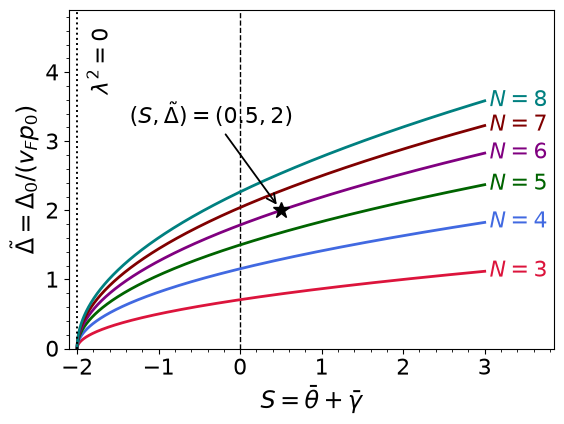

In [8]:
###################################################
# FIGURE 2: COMMENSURATE RESONANCE PHASE DIAGRAM  #
###################################################

fig, ax_map = plt.subplots(figsize=(5.8, 4.4))
S = -2.0 + 5.0 * np.linspace(0.0, 1.0, 600) ** 2
colors_N = {3: 'crimson', 4: 'royalblue', 5: 'darkgreen', 6: 'purple', 7: 'maroon', 8: 'teal'}

for N in range(3, 9):
    col = colors_N[N]
    d_curve = Delta_of_S_N(S, N)
    ax_map.plot(S, d_curve, color=col, linewidth=2.0)
    ax_map.text(3.06, Delta_of_S_N(3.0, N), rf'$N={N}$', color=col,
                fontsize=16, va='center', fontweight='bold' if N == 6 else 'normal')

ax_map.plot([0.5], [2.0], marker='*', color='black', markersize=12, zorder=6)
ax_map.annotate(r'$(S,\tilde{\Delta})=(0.5,2)$',
                xy=(0.5, 2.0), xytext=(-0.35, 3.25),
                fontsize=16, ha='center',
                arrowprops=dict(arrowstyle='->', lw=1.3, color='black', shrinkA=2, shrinkB=5))

ax_map.axvline(-2, color='black', linestyle=':', linewidth=1.4)
ax_map.axvline(0, color='black', linestyle='--', linewidth=1.0, zorder=0)
ax_map.text(-1.88, 4.65, r'$\lambda^2 = 0$', fontsize=16,
            rotation=90, va='top', ha='left', color='black')

ax_map.set_xlabel(r'$S = \bar{\theta} + \bar{\gamma}$', fontsize=17)
ax_map.set_ylabel(r'$\tilde{\Delta} = \Delta_0 / (v_F p_0)$', fontsize=17)
ax_map.tick_params(axis='both', which='major', labelsize=15.5)
ax_map.set_xlim(-2.10, 3.85)
ax_map.set_ylim(0, 4.9)
ax_map.xaxis.set_minor_locator(AutoMinorLocator(5))
ax_map.yaxis.set_minor_locator(AutoMinorLocator(5))

fig.tight_layout()
save_figure(fig, 'fig_resonance')
plt.show()


## 3. Exact Closed Orbits: Rose Curves versus $N$-Cusped Hypocycloids

At each commensurate resonance $\Gamma_+/\Gamma_- = N - 1$ ($N \ge 3$), the closed centroid trajectory over one slow period $T = 2\pi/\Gamma_-$ depends sensitively on the initial quantum state:
- **Tilted vacuum** $|0\rangle_A \otimes (\cos\frac{\phi}{2}|\uparrow\rangle + e^{i\chi}\sin\frac{\phi}{2}|\downarrow\rangle)$: equal counter-rotating amplitudes $|A_+|/|A_-| = 1$ trace an **$N$-petal rose curve** passing $N$ times through the guiding centre.
- **Weakly displaced orbital packet** $|\alpha\rangle_A \otimes |\uparrow\rangle$ ($|\alpha| \ll 1$): opposite amplitude balance $|A_+|/|A_-| = \Gamma_-/\Gamma_+ = (N-1)^{-1}$ traces an **$N$-cusped hypocycloid** avoiding the guiding centre for every $N \ge 3$.

Saved: fig_orbits.pdf and fig_orbits.png to d:\COOLYEAH\Research\Non-Commutativity\Draft split\PaperB_exact-main(1)\PaperB_exact-main\New Draft\figures


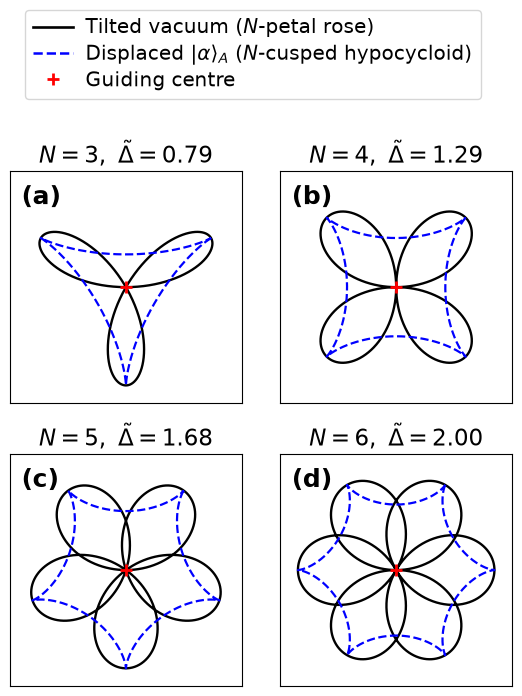

In [9]:
###################################################
# FIGURE 3: CLOSED ORBITS (ROSE VS HYPOCYCLOID)   #
###################################################

S_bench = 0.5
th = ga = S_bench / 2

fig, axs = plt.subplots(2, 2, figsize=(6.6, 7.8))
fig.subplots_adjust(wspace=0.12, hspace=0.22, top=0.77)

orbit_specs = [
    (3, "(a)", axs[0, 0]),
    (4, "(b)", axs[0, 1]),
    (5, "(c)", axs[1, 0]),
    (6, "(d)", axs[1, 1]),
]

for N, tag, sub in orbit_specs:
    D = Delta_of_S_N(S_bench, N)
    E, Gp, Gm = gammas(th, ga, D)
    taus = np.linspace(0, 2 * np.pi / Gm, 3000)

    Z_rose = exact_Z(th, ga, D, 1.0, 0.0, taus)
    rmax_rose = np.max(np.abs(Z_rose))
    phase_align = np.exp(1j * (np.pi / 2 - np.pi / N))
    Z_hypo = phase_align * (np.exp(-1j * Gm * taus) + (Gm / Gp) * np.exp(1j * Gp * taus))
    Z_hypo = Z_hypo / np.max(np.abs(Z_hypo)) * rmax_rose

    sub.plot(Z_rose.real, Z_rose.imag, color='black', linewidth=1.7)
    sub.plot(Z_hypo.real, Z_hypo.imag, color='blue', linestyle='--', linewidth=1.6)
    sub.plot(0, 0, marker='+', color='red', markersize=9, mew=2.0, zorder=5)

    sub.set_aspect('equal', 'box')
    lim = rmax_rose * 1.18
    sub.set_xlim(-lim, lim)
    sub.set_ylim(-lim, lim)
    sub.set_xticks([])
    sub.set_yticks([])
    sub.text(0.05, 0.94, tag, transform=sub.transAxes,
             fontsize=18, fontweight='bold', va='top')
    sub.set_title(rf'$N={N},\ \tilde{{\Delta}}={D:.2f}$', fontsize=16.5, pad=6)

handles = [
    plt.Line2D([0], [0], color='black', linestyle='-', linewidth=1.9,
               label=r'Tilted vacuum ($N$-petal rose)'),
    plt.Line2D([0], [0], color='blue', linestyle='--', linewidth=1.8,
               label=r'Displaced $|\alpha\rangle_A$ ($N$-cusped hypocycloid)'),
    plt.Line2D([0], [0], color='red', marker='+', linestyle='none',
               markersize=9, mew=2.0, label='Guiding centre'),
]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.99),
           ncol=1, frameon=True, facecolor='white', edgecolor='0.8',
           fontsize=14.5, labelspacing=0.28, handletextpad=0.6)

save_figure(fig, 'fig_orbits')
plt.show()


## 4. Uniform Electric Force and Relativistic Hall Drift

Subjecting the non-commutative Dirac oscillator to a uniform electric force $-\varepsilon\hat{\mathbf{x}}$ alters the Hamiltonian to:
\begin{align}
\hat{H}' = \hat{H} - \varepsilon \hat{X}.
\end{align}

Decomposing the physical position into dynamical and guiding-centre variables:
\begin{align}
\hat{X} = \hat{R}_x - \frac{1+\bar{\theta}}{\lambda^2}\hat{q}_y, \quad \hat{Y} = \hat{R}_y + \frac{1+\bar{\theta}}{\lambda^2}\hat{q}_x,
\end{align}
yields a strictly constant, non-dispersive **guiding-centre Hall drift**:
\begin{align}
v_{\mathrm{d}} = \frac{d\hat{R}_y}{d\tau} = \varepsilon \frac{1 - \bar{\theta}\bar{\gamma}}{2 + \bar{\theta} + \bar{\gamma}} = \varepsilon \frac{1 - \bar{\theta}\bar{\gamma}}{\lambda^2}.
\end{align}

Key physical consequences:
1. **Critical Drift Cancellation**: At $\bar{\theta}\bar{\gamma} = 1$, the Hall drift velocity vanishes identically ($v_{\mathrm{d}} = 0$) regardless of field strength $\varepsilon$.
2. **Laboratory-Frame Coherent Translation**: At $\varepsilon=0.12$, the closed star pattern translates uniformly in the transverse $\hat{\mathbf{y}}$ direction without unravelling.
3. **Relativistic Retuning**: In the co-moving frame, a slight frequency shift due to the Lorentz boost factor $\gamma_L = 1/\sqrt{1-u^2}$ can be precisely countered by retuning $S$ from $0.500$ to $0.505$.

Saved: fig_hall_drift.pdf and fig_hall_drift.png to d:\COOLYEAH\Research\Non-Commutativity\Draft split\PaperB_exact-main(1)\PaperB_exact-main\New Draft\figures


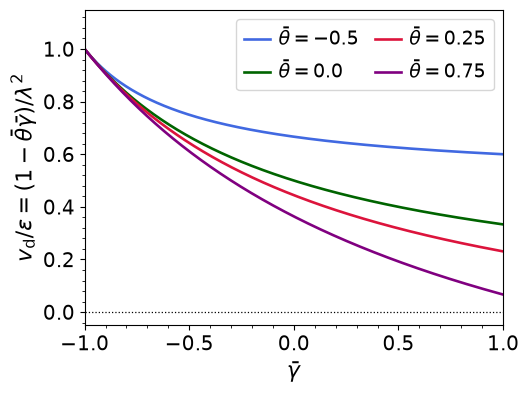

In [10]:
###################################################
# FIGURE 4: HALL-DRIFT COEFFICIENT VS GAMMA_BAR   #
###################################################

fig, ax1 = plt.subplots(figsize=(5.4, 4.1))

theta_configs = [
    (-0.5, 'royalblue', r'$\bar{\theta}=-0.5$'),
    (0.0, 'darkgreen', r'$\bar{\theta}=0.0$'),
    (0.25, 'crimson', r'$\bar{\theta}=0.25$'),
    (0.75, 'purple', r'$\bar{\theta}=0.75$'),
]
g = np.linspace(-1.0, 1.0, 800)
for t_val, col, lab in theta_configs:
    l2 = 2.0 + t_val + g
    vd = (1.0 - t_val * g) / l2
    ax1.plot(g, vd, color=col, linewidth=1.9, label=lab)
ax1.axhline(0, color='black', linewidth=0.9, linestyle=':')
ax1.set_xlim(-1.0, 1.0)
ax1.set_ylim(-0.05, 1.15)
ax1.set_xlabel(r'$\bar{\gamma}$', fontsize=16)
ax1.set_ylabel(r'$v_{\mathrm{d}}/\varepsilon = (1-\bar{\theta}\bar{\gamma})/\lambda^2$', fontsize=16)
ax1.tick_params(axis='both', which='major', labelsize=14.5)
ax1.xaxis.set_minor_locator(AutoMinorLocator(5))
ax1.yaxis.set_minor_locator(AutoMinorLocator(5))
ax1.legend(frameon=True, facecolor='white', edgecolor='0.8', loc='upper right',
           ncol=2, fontsize=13.5, columnspacing=0.8, handlelength=1.4, handletextpad=0.45)

save_figure(fig, 'fig_hall_drift')
plt.show()


Saved: fig_efield.pdf and fig_efield.png to d:\COOLYEAH\Research\Non-Commutativity\Draft split\PaperB_exact-main(1)\PaperB_exact-main\New Draft\figures


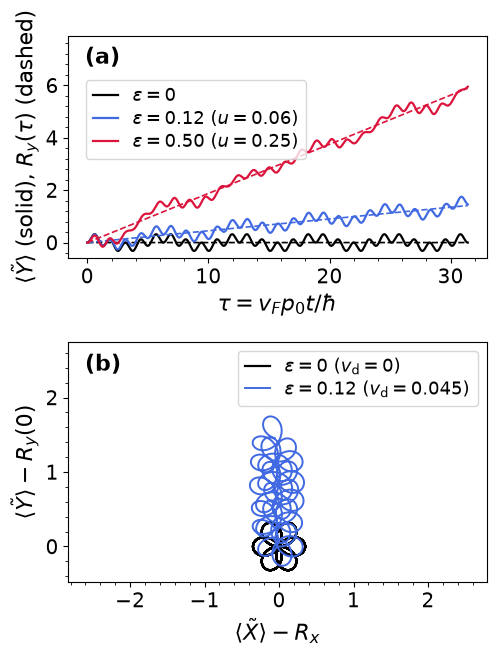

In [11]:
###################################################
# FIGURE 5: HALL TRANSLATION OF THE N=6 STAR      #
###################################################

def reduced_evolution(th, ga, D, phi, chi, eps, taus, nf=250):
    o = one_mode_ops(th, ga, D, nf)
    lam2, mu = o['lam2'], 1 + th
    u = eps * mu / lam2
    ev = Evolver(o['h'] - u * o['qy'], one_mode_state(phi, chi, nf))
    qx = ev.expect(o['qx'], taus).real
    qy = ev.expect(o['qy'], taus).real
    vd = eps * (1 - th * ga) / lam2
    X = -mu / lam2 * qy
    Y = vd * taus + mu / lam2 * qx
    return X, Y, vd * taus, vd, u

Delta, N, phi = 2.0, 6, 1.0
th = ga = 0.25
E, Gp, Gm = gammas(th, ga, Delta)
T = 2 * np.pi / Gm
taus = np.linspace(0, 5 * T, 3200)

fig, axs = plt.subplots(2, 1, figsize=(5.4, 7.1), gridspec_kw={'height_ratios': [1.0, 1.08]})
fig.subplots_adjust(hspace=0.36)

ax1 = axs[0]
eps_configs = [
    (0.0, 'black', r'$\varepsilon=0$'),
    (0.12, 'royalblue', r'$\varepsilon=0.12$ ($u=0.06$)'),
    (0.50, 'crimson', r'$\varepsilon=0.50$ ($u=0.25$)'),
]
for eps, col, lab in eps_configs:
    X, Y, Ry, vd, u = reduced_evolution(th, ga, Delta, phi, 0.0, eps, taus)
    ax1.plot(taus, Y, color=col, linewidth=1.6, label=lab)
    ax1.plot(taus, Ry, color=col, linestyle='--', linewidth=1.2)
ax1.set_xlabel(r'$\tau = v_F p_0 t / \hbar$', fontsize=16)
ax1.set_ylabel(r'$\langle\tilde{Y}\rangle$ (solid), $R_y(\tau)$ (dashed)', fontsize=15.5)
ax1.tick_params(axis='both', which='major', labelsize=14.5)
ax1.set_ylim(-0.6, 7.9)
ax1.xaxis.set_minor_locator(AutoMinorLocator(5))
ax1.yaxis.set_minor_locator(AutoMinorLocator(5))
ax1.legend(frameon=True, facecolor='white', edgecolor='0.8', loc='upper left',
           bbox_to_anchor=(0.02, 0.84), fontsize=13.0, handlelength=1.4, labelspacing=0.25)
ax1.text(0.04, 0.95, '(a)', transform=ax1.transAxes, fontsize=16, fontweight='bold', va='top')

ax2 = axs[1]
X0, Y0, *_ = reduced_evolution(th, ga, Delta, phi, 0.0, 0.0, taus)
X1, Y1, *_ = reduced_evolution(th, ga, Delta, phi, 0.0, 0.12, taus)
ax2.plot(X0, Y0, color='black', linewidth=1.6, label=r'$\varepsilon=0$ ($v_{\mathrm{d}}=0$)')
ax2.plot(X1, Y1, color='royalblue', linewidth=1.4, label=r'$\varepsilon=0.12$ ($v_{\mathrm{d}}=0.045$)')
ax2.set_aspect('equal', 'datalim')
ax2.set_xlabel(r'$\langle\tilde{X}\rangle - R_x$', fontsize=16)
ax2.set_ylabel(r'$\langle\tilde{Y}\rangle - R_y(0)$', fontsize=16)
ax2.tick_params(axis='both', which='major', labelsize=14.5)
ax2.set_ylim(-0.48, 2.75)
ax2.xaxis.set_minor_locator(AutoMinorLocator(5))
ax2.yaxis.set_minor_locator(AutoMinorLocator(5))
ax2.legend(frameon=True, facecolor='white', edgecolor='0.8', loc='upper right',
           fontsize=13.0, handlelength=1.4, labelspacing=0.25)
ax2.text(0.04, 0.95, '(b)', transform=ax2.transAxes, fontsize=16, fontweight='bold', va='top')

save_figure(fig, 'fig_efield')
plt.show()


Saved: fig_comoving.pdf and fig_comoving.png to d:\COOLYEAH\Research\Non-Commutativity\Draft split\PaperB_exact-main(1)\PaperB_exact-main\New Draft\figures


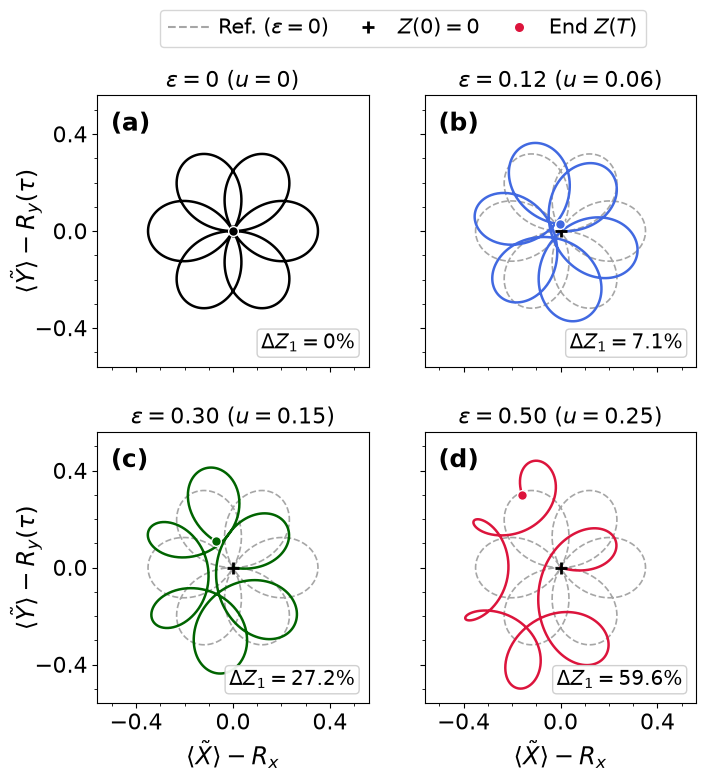

In [21]:
###################################################
# FIGURE 6: CO-MOVING ORBIT MISMATCH VS EPSILON   #
###################################################

taus_1T = np.linspace(0, T, 1000)
taus_5T = np.linspace(0, 5 * T, 1001)
X0_1T, Y0_1T, Ry0_1T, *_ = reduced_evolution(th, ga, Delta, phi, 0.0, 0.0, taus_1T)

fig, axs = plt.subplots(2, 2, figsize=(8.0, 8.0), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.12, hspace=0.24, top=0.87)

panels = [
    (0, 0, 0.00, 0.00, '(a)', 'black'),
    (0, 1, 0.12, 0.06, '(b)', 'royalblue'),
    (1, 0, 0.30, 0.15, '(c)', 'darkgreen'),
    (1, 1, 0.50, 0.25, '(d)', 'crimson'),
]

for r_idx, c_idx, eps, u_val, tag, col in panels:
    ax = axs[r_idx, c_idx]
    Xc, Yc, Ryc, *_ = reduced_evolution(th, ga, Delta, phi, 0.0, eps, taus_1T)
    X5, Y5, Ry5, *_ = reduced_evolution(th, ga, Delta, phi, 0.0, eps, taus_5T)
    z5_max = np.max(np.hypot(X5, Y5 - Ry5))
    dz1 = np.hypot(Xc[-1] - Xc[0], (Yc - Ryc)[-1] - (Yc - Ryc)[0]) / z5_max * 100.0

    if eps > 0:
        ax.plot(X0_1T, Y0_1T - Ry0_1T, color='0.65', linestyle='--', linewidth=1.2, zorder=1)
    ax.plot(Xc, Yc - Ryc, color=col, linewidth=1.8, zorder=3)
    ax.plot(0, 0, marker='+', color='black', markersize=9, mew=2.0, zorder=5)
    ax.plot(Xc[-1], (Yc - Ryc)[-1], marker='o', color=col, markersize=7.0,
            markeredgecolor='white', markeredgewidth=1.0, zorder=6)

    ax.set_aspect('equal', 'box')
    ax.set_xlim(-0.56, 0.56)
    ax.set_ylim(-0.56, 0.56)
    ax.set_xticks([-0.4, 0.0, 0.4])
    ax.set_yticks([-0.4, 0.0, 0.4])
    ax.yaxis.set_label_coords(-0.2, 0.5)
    ax.tick_params(axis='both', which='major', labelsize=15.5)
    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))
    if r_idx == 1:
        ax.set_xlabel(r'$\langle\tilde{X}\rangle - R_x$', fontsize=17.5)
    if c_idx == 0:
        ax.set_ylabel(r'$\langle\tilde{Y}\rangle - R_y(\tau)$', fontsize=17.5)
    ax.set_title(rf'$\varepsilon={eps:.2f}$ ($u={u_val:.2f}$)' if eps > 0 else r'$\varepsilon=0$ ($u=0$)',
                 fontsize=16, pad=6)
    ax.text(0.05, 0.94, tag, transform=ax.transAxes, fontsize=18, fontweight='bold', va='top')
    ax.text(0.95, 0.05, rf'$\Delta Z_1={dz1:.1f}\%$' if eps > 0 else r'$\Delta Z_1=0\%$',
            transform=ax.transAxes, fontsize=14.5, ha='right', va='bottom',
            bbox=dict(boxstyle='round,pad=0.20', fc='white', ec='0.8', alpha=0.92))

handles = [
    plt.Line2D([0], [0], color='0.65', linestyle='--', linewidth=1.5, label=r'Ref. ($\varepsilon=0$)'),
    plt.Line2D([0], [0], color='black', marker='+', linestyle='none', markersize=9, mew=2.0, label=r'$Z(0)=0$'),
    plt.Line2D([0], [0], color='crimson', marker='o', linestyle='none', markersize=7.5,
               markeredgecolor='white', markeredgewidth=1.0, label=r'End $Z(T)$'),
]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.52, 0.99),
           ncol=3, frameon=True, facecolor='white', edgecolor='0.8',
           fontsize=14.8, columnspacing=0.9, handletextpad=0.45)

save_figure(fig, 'fig_comoving')
plt.show()


## 5. Relativistic Lorentz Boost Spectrum and Geometric Closure Mismatch

Under the non-commutative Lorentz boost with dimensionless boost velocity:
\begin{align}
u = \frac{\varepsilon(1+\bar{\theta})}{\lambda^2}, \quad u < 1,
\end{align}
the electric field is eliminated in the co-moving frame. The positive relativistic energy eigenvalues are given by:
\begin{align}
\varepsilon_n^+ = \sqrt{(1-u^2)\tilde{\Delta}^2 + 2n\lambda^2(1-u^2)^{3/2}}, \quad n = 0, 1, 2, \dots
\end{align}

We benchmark this analytical formula against truncated Fock-space exact diagonalisation ($N_{\mathrm{Fock}} = 300$).

Furthermore, to quantify the orbit stability under electric drift, we evaluate the **relative co-moving closure mismatch**:
\begin{align}
\Delta Z_m = \frac{|Z(mT) - Z(0)|}{\max_{\tau} |Z(\tau)|},
\end{align}
after $m=1$ and $m=5$ field-free slow periods $T = 2\pi/\Gamma_-$.

Saved: fig_boost.pdf and fig_boost.png to d:\COOLYEAH\Research\Non-Commutativity\Draft split\PaperB_exact-main(1)\PaperB_exact-main\New Draft\figures


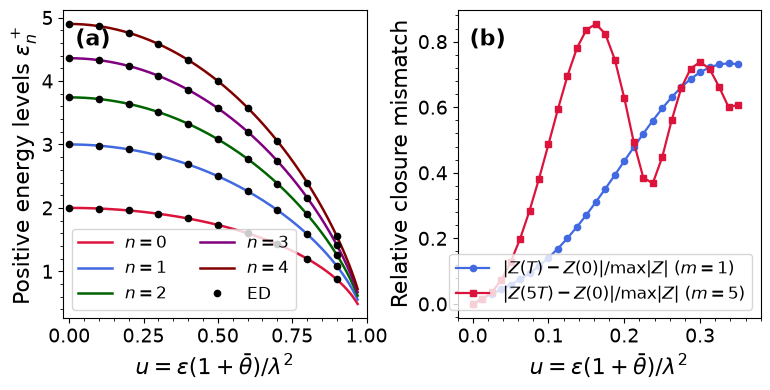

In [13]:
###################################################
# FIGURE 5: RELATIVISTIC BOOST SPECTRUM & MISMATCH#
###################################################

#----------#
# PREAMBLE #
#----------#

th, ga, D = 0.25, 0.25, 2.0
nf = 300
o = one_mode_ops(th, ga, D, nf)
lam2 = o['lam2']
us = np.linspace(0, 0.9, 10)

fig, ax = plt.subplots(1, 2, figsize=(9.0, 4.0))
fig.subplots_adjust(wspace=0.30)

#-----------#
# MAIN PART #
#-----------#

# Subplot (a): Boosted spectrum vs ED
uu = np.linspace(0, 0.97, 300)
colors_levels = ['crimson', 'royalblue', 'darkgreen', 'purple', 'maroon']
for n in range(5):
    b = 1 - uu ** 2
    if n == 0:
        ax[0].plot(uu, D * np.sqrt(b), color=colors_levels[n], linewidth=1.8, label=r'$n=0$')
    else:
        ax[0].plot(uu, np.sqrt(b * D ** 2 + 2 * n * lam2 * b ** 1.5), color=colors_levels[n],
                   linewidth=1.8, label=rf'$n={n}$')

for k, u in enumerate(us):
    w = np.linalg.eigvalsh(o['h'] - u * o['qy'])
    pos = np.sort(w[w > 0])[:5]
    ax[0].plot([u] * len(pos), pos, marker='o', color='black', markersize=4.5,
               linestyle='none', label='ED' if k == 0 else None)

ax[0].set_xlabel(r'$u = \varepsilon(1+\bar{\theta})/\lambda^2$')
ax[0].set_ylabel(r'Positive energy levels $\varepsilon_n^+$')
ax[0].set_xlim(-0.02, 1.00)
ax[0].xaxis.set_minor_locator(AutoMinorLocator(5))
ax[0].yaxis.set_minor_locator(AutoMinorLocator(5))
ax[0].legend(frameon=True, facecolor='white', edgecolor='0.8', ncol=2, loc='lower left', fontsize=SMALL_SIZE)
ax[0].text(0.04, 0.94, '(a)', transform=ax[0].transAxes, fontsize=BIGGER_SIZE, fontweight='bold', va='top')

# Subplot (b): Closure mismatch of co-moving star
E, Gp, Gm = gammas(th, ga, D)
T = 2 * np.pi / Gm
mu = 1 + th
epss = np.linspace(0, 0.7, 29)
err1, err5 = [], []
nfc = 200
oc = one_mode_ops(th, ga, D, nfc)
ts = np.linspace(0, 5 * T, 1001)

for eps in epss:
    u = eps * mu / lam2
    ev = Evolver(oc['h'] - u * oc['qy'], one_mode_state(1.0, 0.0, nfc))
    z = mu / lam2 * (-ev.expect(oc['qy'], ts) + 1j * ev.expect(oc['qx'], ts))
    size = np.max(np.abs(z))
    z1 = mu / lam2 * (-ev.expect(oc['qy'], np.array([T])) + 1j * ev.expect(oc['qx'], np.array([T])))[0]
    err1.append(abs(z1 - z[0]) / size)
    err5.append(abs(z[-1] - z[0]) / size)

ax[1].plot(epss * mu / lam2, err1, marker='o', color='royalblue', linestyle='-', 
           linewidth=1.6, markersize=4.5, label=r'$|Z(T)-Z(0)|/\max|Z|$ ($m=1$)')
ax[1].plot(epss * mu / lam2, err5, marker='s', color='crimson', linestyle='-', 
           linewidth=1.6, markersize=4.5, label=r'$|Z(5T)-Z(0)|/\max|Z|$ ($m=5$)')

ax[1].set_xlabel(r'$u = \varepsilon(1+\bar{\theta})/\lambda^2$')
ax[1].set_ylabel(r'Relative closure mismatch')
ax[1].set_xlim(-0.02, 0.38)
ax[1].xaxis.set_minor_locator(AutoMinorLocator(5))
ax[1].yaxis.set_minor_locator(AutoMinorLocator(5))
ax[1].legend(frameon=True, facecolor='white', edgecolor='0.8', loc='lower right', fontsize=SMALL_SIZE)
ax[1].text(0.04, 0.94, '(b)', transform=ax[1].transAxes, fontsize=BIGGER_SIZE, fontweight='bold', va='top')

# Save figure in PDF and PNG formats
save_figure(fig, 'fig_boost')
plt.show()


## Summary and Verification Results

All 7 publication figures have been produced using the DiracTE styling template and exported:
1. `fig_dynamics.pdf` & `fig_dynamics.png`: Exact quantum dynamics in resonant ($N=6$) and off-resonant regimes.
2. `fig_resonance.pdf` & `fig_resonance.png`: Commensurability phase diagram $\tilde{\Delta}_N(S)$ in the $(S,\tilde{\Delta})$ plane for $N=3,\dots,8$.
3. `fig_orbits.pdf` & `fig_orbits.png`: Closed $N$-petal rose curves and $N$-cusped hypocycloids for $N=3,4,5,6$ at $S=0.5$.
4. `fig_hall_drift.pdf` & `fig_hall_drift.png`: Guiding-centre Hall-drift coefficient $v_{\mathrm{d}}/\varepsilon$ vs $\bar{\gamma} \in (-1,1)$ for fixed $\bar{\theta} \in (-1,1)$.
5. `fig_efield.pdf` & `fig_efield.png`: Hall translation of the $N=6$ star (transverse centroid/guiding centre and lab-frame orbit).
6. `fig_comoving.pdf` & `fig_comoving.png`: Co-moving one-period trajectories across $\varepsilon = 0, 0.12, 0.30, 0.50$ illustrating progressive trajectory mismatch.
7. `fig_boost.pdf` & `fig_boost.png`: Relativistic Lorentz-boosted spectrum vs exact diagonalisation and closure mismatch.

The updated figures have also been integrated directly into the manuscript `main.tex`.